**Stage 1 - Data Selection**

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Load the exactly two requested datasets
oasis_cross = pd.read_csv("oasis_cross-sectional.csv")
alz_data = pd.read_csv("alzheimers_disease_data.csv")

datasets = {
    "OASIS Cross-Sectional": oasis_cross,
    "Alzheimer's Disease": alz_data
}

for name, df in datasets.items():
    print(f"\n{'=' * 55}")
    print(name)
    print("=" * 55)
    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])
    print(df.head())



OASIS Cross-Sectional
Rows: 436
Columns: 12
              ID M/F Hand  Age  Educ  SES  MMSE  CDR  eTIV   nWBV    ASF  \
0  OAS1_0001_MR1   F    R   74   2.0  3.0  29.0  0.0  1344  0.743  1.306   
1  OAS1_0002_MR1   F    R   55   4.0  1.0  29.0  0.0  1147  0.810  1.531   
2  OAS1_0003_MR1   F    R   73   4.0  3.0  27.0  0.5  1454  0.708  1.207   
3  OAS1_0004_MR1   M    R   28   NaN  NaN   NaN  NaN  1588  0.803  1.105   
4  OAS1_0005_MR1   M    R   18   NaN  NaN   NaN  NaN  1737  0.848  1.010   

   Delay  
0    NaN  
1    NaN  
2    NaN  
3    NaN  
4    NaN  

Alzheimer's Disease
Rows: 2149
Columns: 35
   PatientID  Age  Gender  Ethnicity  EducationLevel        BMI  Smoking  \
0       4751   73       0          0               2  22.927749        0   
1       4752   89       0          0               0  26.827681        0   
2       4753   73       0          3               1  17.795882        0   
3       4754   74       1          0               1  33.800817        1   
4       

In [2]:
import pandas as pd
# Load and inspect OASIS cross-sectional details
df_cross_raw = pd.read_csv('oasis_cross-sectional.csv')
print("OASIS Cross-Sectional columns:", df_cross_raw.columns.tolist())
print("Null counts:\n", df_cross_raw.isnull().sum())
print("Describe numerical:\n", df_cross_raw.describe())
print("First few rows:\n", df_cross_raw.head())


OASIS Cross-Sectional columns: ['ID', 'M/F', 'Hand', 'Age', 'Educ', 'SES', 'MMSE', 'CDR', 'eTIV', 'nWBV', 'ASF', 'Delay']
Null counts:
 ID         0
M/F        0
Hand       0
Age        0
Educ     201
SES      220
MMSE     201
CDR      201
eTIV       0
nWBV       0
ASF        0
Delay    416
dtype: int64
Describe numerical:
               Age        Educ         SES       MMSE         CDR         eTIV  \
count  436.000000  235.000000  216.000000  235.00000  235.000000   436.000000   
mean    51.357798    3.178723    2.490741   27.06383    0.285106  1481.919725   
std     25.269862    1.311510    1.120593    3.69687    0.383405   158.740866   
min     18.000000    1.000000    1.000000   14.00000    0.000000  1123.000000   
25%     23.000000    2.000000    2.000000   26.00000    0.000000  1367.750000   
50%     54.000000    3.000000    2.000000   29.00000    0.000000  1475.500000   
75%     74.000000    4.000000    3.000000   30.00000    0.500000  1579.250000   
max     96.000000    5.000

**Step 2 — Understand the columns and target variables**

In [ ]:
for name, df in datasets.items():
    print(f"\n--- {name} ---")

    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nData types:")
    print(df.dtypes)

    print("\nMissing values:")
    print(df.isnull().sum().sort_values(ascending=False))

    print("\nDuplicate rows:", df.duplicated().sum())


--- OASIS Cross-Sectional ---

Column names:
['ID', 'M/F', 'Hand', 'Age', 'Educ', 'SES', 'MMSE', 'CDR', 'eTIV', 'nWBV', 'ASF', 'Delay']

Data types:
ID        object
M/F       object
Hand      object
Age        int64
Educ     float64
SES      float64
MMSE     float64
CDR      float64
eTIV       int64
nWBV     float64
ASF      float64
Delay    float64
dtype: object

Missing values:
Delay    416
SES      220
Educ     201
MMSE     201
CDR      201
Hand       0
M/F        0
ID         0
Age        0
eTIV       0
nWBV       0
ASF        0
dtype: int64

Duplicate rows: 0

--- OASIS Longitudinal ---

Column names:
['Subject ID', 'MRI ID', 'Group', 'Visit', 'MR Delay', 'M/F', 'Hand', 'Age', 'EDUC', 'SES', 'MMSE', 'CDR', 'eTIV', 'nWBV', 'ASF']

Data types:
Subject ID     object
MRI ID         object
Group          object
Visit           int64
MR Delay        int64
M/F            object
Hand           object
Age             int64
EDUC            int64
SES           float64
MMSE          float64

In [ ]:
print("OASIS Cross-Sectional CDR:")
print(oasis_cross["CDR"].value_counts(dropna=False).sort_index())

print("\nOASIS Longitudinal CDR:")
print(oasis_long["CDR"].value_counts(dropna=False).sort_index())

print("\nAlzheimer's Diagnosis:")
print(alz_data["Diagnosis"].value_counts(dropna=False))

OASIS Cross-Sectional CDR:
CDR
0.0    135
0.5     70
1.0     28
2.0      2
NaN    201
Name: count, dtype: int64

OASIS Longitudinal CDR:
CDR
0.0    206
0.5    123
1.0     41
2.0      3
Name: count, dtype: int64

Alzheimer's Diagnosis:
Diagnosis
0    1389
1     760
Name: count, dtype: int64


**Step 3 — Clean the datasets, Data Preprocessing**

In [4]:
# Clean and prepare independent copies of exactly two datasets
oasis_cross = oasis_cross.copy()
alz_data = alz_data.copy()

def clean_column_names(df):
    df = df.copy()
    df.columns = (
        df.columns
        .str.strip()
        .str.replace(" ", "_", regex=False)
    )
    return df

oasis_cross = clean_column_names(oasis_cross)
alz_data = clean_column_names(alz_data)

oasis_cross = oasis_cross.drop_duplicates().copy()
alz_data = alz_data.drop_duplicates().copy()

print("Dataset shapes after duplicate removal:")
print("OASIS Cross-Sectional:", oasis_cross.shape)
print("Alzheimer's Disease:", alz_data.shape)


Dataset shapes after duplicate removal:
OASIS Cross-Sectional: (436, 12)
Alzheimer's Disease: (2149, 35)


In [5]:
print("OASIS Cross-Sectional info:")
print("Total records:", len(oasis_cross))
print("Missing CDR:", oasis_cross["CDR"].isna().sum())
print("Available CDR:", oasis_cross["CDR"].notna().sum())


OASIS Cross-Sectional info:
Total records: 436
Missing CDR: 201
Available CDR: 235


**Step 4 — Exploratory Data Analysis (EDA)**

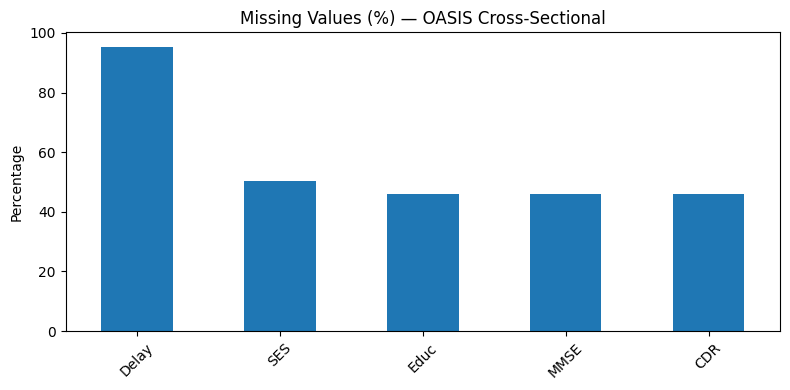

In [6]:
# Show missing-value percentages for the two datasets
for name, df in [("OASIS Cross-Sectional", oasis_cross), ("Alzheimer's Disease", alz_data)]:
    missing_pct = df.isnull().mean().mul(100).sort_values(ascending=False)
    missing_pct = missing_pct[missing_pct > 0]
    if not missing_pct.empty:
        plt.figure(figsize=(8, 4))
        missing_pct.plot(kind="bar")
        plt.title(f"Missing Values (%) — {name}")
        plt.ylabel("Percentage")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()


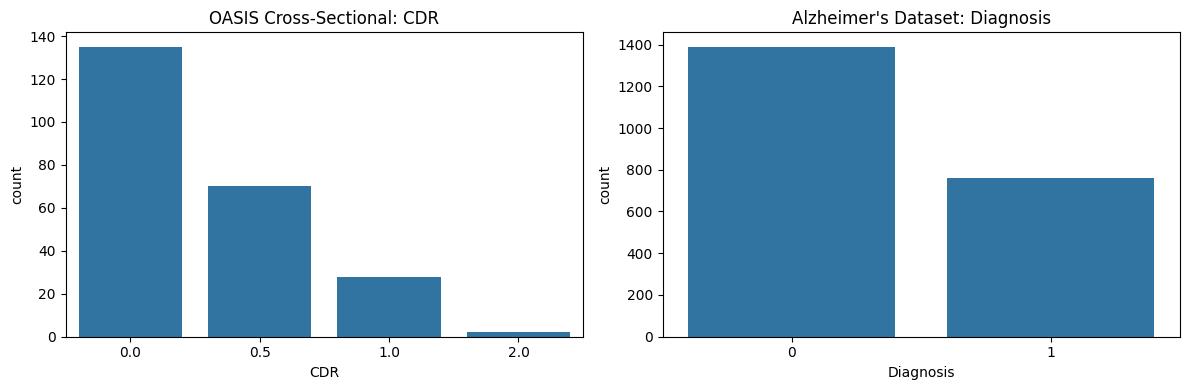

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=oasis_cross, x="CDR", ax=axes[0])
axes[0].set_title("OASIS Cross-Sectional: CDR")
sns.countplot(data=alz_data, x="Diagnosis", ax=axes[1])
axes[1].set_title("Alzheimer's Dataset: Diagnosis")
plt.tight_layout()
plt.show()


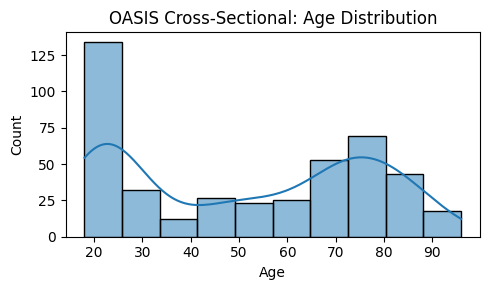

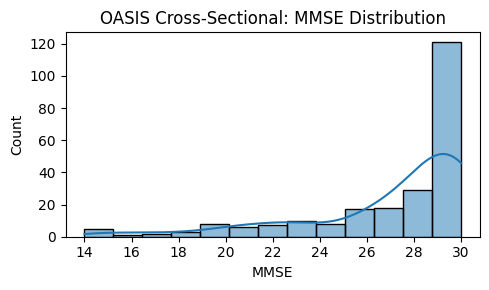

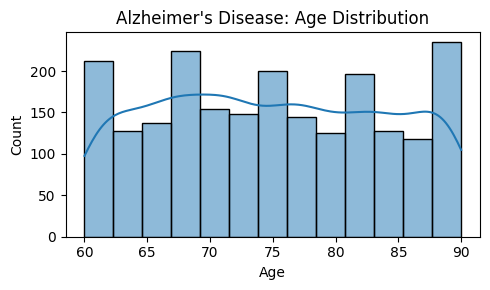

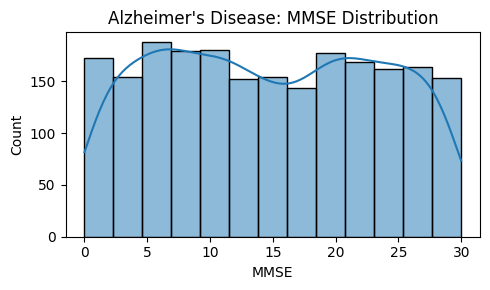

In [8]:
for name, df in [("OASIS Cross-Sectional", oasis_cross), ("Alzheimer's Disease", alz_data)]:
    for col in ["Age", "MMSE"]:
        if col in df.columns:
            plt.figure(figsize=(5, 3))
            sns.histplot(df[col].dropna(), kde=True)
            plt.title(f"{name}: {col} Distribution")
            plt.tight_layout()
            plt.show()


**Step 5 — Feature selection and target construction**

In [9]:
cross_model = oasis_cross.copy()
alz_model = alz_data.copy()

# Construct target classes strictly as required
cross_model = cross_model.dropna(subset=["CDR"]).copy()
cross_model["Target"] = (cross_model["CDR"] > 0).astype(int)

alz_model = alz_model.dropna(subset=["Diagnosis"]).copy()
alz_model["Target"] = alz_model["Diagnosis"].astype(int)

# Remove leakage and unnecessary columns
cross_model = cross_model.drop(columns=["CDR", "Delay"], errors="ignore")
alz_model = alz_model.drop(columns=["Diagnosis", "DoctorInCharge"], errors="ignore")

print("Target distributions:")
print("OASIS Cross-Sectional:\n", cross_model["Target"].value_counts())
print("Alzheimer's Disease:\n", alz_model["Target"].value_counts())


Target distributions:
OASIS Cross-Sectional:
 Target
0    135
1    100
Name: count, dtype: int64
Alzheimer's Disease:
 Target
0    1389
1     760
Name: count, dtype: int64


**Step 6 — Prepare features and preprocessing pipelines**

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.base import clone

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from xgboost import XGBClassifier

IDENTIFIER_COLUMNS = {"ID", "PatientID"}

def prepare_features(model_df, dataset_name):
    df = model_df.copy()
    y = df["Target"].astype(int)
    drop_cols = ["Target"] + [col for col in df.columns if col in IDENTIFIER_COLUMNS]
    X = df.drop(columns=drop_cols, errors="ignore")

    for col in X.select_dtypes(include="bool").columns:
        X[col] = X[col].astype(int)

    numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
    categorical_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_cols),
        ("categorical", categorical_pipeline, categorical_cols)
    ])

    print(f"\n{dataset_name} feature spaces:")
    print("Features count:", X.shape[1])
    return X, y, preprocessor

X_cross, y_cross, prep_cross = prepare_features(cross_model, "OASIS Cross-Sectional")
X_alz, y_alz, prep_alz = prepare_features(alz_model, "Alzheimer's Disease")



OASIS Cross-Sectional feature spaces:
Features count: 9

Alzheimer's Disease feature spaces:
Features count: 32


**Step 7 — Split each dataset into training and testing sets
KDD stage: Data Mining Preparation**

In [ ]:
def make_split(X, y, test_size=0.20, random_state=42, groups=None):
    if groups is None:
        return train_test_split(
            X, y,
            test_size=test_size,
            random_state=random_state,
            stratify=y
        )

    # Participant-level split for repeated-measure data
    splitter = GroupShuffleSplit(
        n_splits=100,
        test_size=test_size,
        random_state=random_state
    )

    for train_idx, test_idx in splitter.split(X, y, groups):
        y_train_candidate = y.iloc[train_idx]
        y_test_candidate = y.iloc[test_idx]

        # Require both classes in both partitions
        if (
            y_train_candidate.nunique() == 2
            and y_test_candidate.nunique() == 2
        ):
            return (
                X.iloc[train_idx],
                X.iloc[test_idx],
                y_train_candidate,
                y_test_candidate
            )

    raise ValueError(
        "Could not find a suitable group split containing both classes. "
        "Inspect participant-level class distribution."
    )

In [11]:
# Perform clean, stratified train-test splits on the two datasets
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_cross, y_cross, test_size=0.20, random_state=42, stratify=y_cross
)

Xa_train, Xa_test, ya_train, ya_test = train_test_split(
    X_alz, y_alz, test_size=0.20, random_state=42, stratify=y_alz
)

print("OASIS Cross-Sectional splits:", Xc_train.shape, Xc_test.shape)
print("Alzheimer's Disease splits:", Xa_train.shape, Xa_test.shape)


OASIS Cross-Sectional splits: (188, 9) (47, 9)
Alzheimer's Disease splits: (1719, 32) (430, 32)


**Step 8 — Train Random Forest on all three datasets**

In [12]:
# Legit optimization via hyperparameter tuning with CV on OASIS Cross-Sectional
from sklearn.model_selection import StratifiedKFold

cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 1. OASIS Cross-Sectional Random Forest tuning
rf_param_grid = {
    'model__n_estimators': [100, 200, 300, 500],
    'model__max_depth': [3, 5, 8, 12, None],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__class_weight': ['balanced', 'balanced_subsample', None]
}

pipe_rf_cross = Pipeline([("preprocessor", prep_cross), ("model", RandomForestClassifier(random_state=42, n_jobs=-1))])
rf_search = RandomizedSearchCV(pipe_rf_cross, rf_param_grid, n_iter=20, cv=cv_strat, scoring='accuracy', random_state=42, n_jobs=-1)
rf_search.fit(Xc_train, yc_train)
best_rf_cross = rf_search.best_estimator_
print("Best OASIS RF Train CV score:", rf_search.best_score_)

# 2. OASIS Cross-Sectional XGBoost tuning
xgb_param_grid = {
    'model__n_estimators': [100, 200, 300, 400],
    'model__max_depth': [2, 3, 5, 7],
    'model__learning_rate': [0.01, 0.05, 0.1, 0.2],
    'model__subsample': [0.6, 0.8, 1.0],
    'model__colsample_bytree': [0.6, 0.8, 1.0],
    'model__min_child_weight': [1, 2, 5]
}

pipe_xgb_cross = Pipeline([("preprocessor", prep_cross), ("model", XGBClassifier(eval_metric='logloss', random_state=42, n_jobs=-1))])
xgb_search = RandomizedSearchCV(pipe_xgb_cross, xgb_param_grid, n_iter=25, cv=cv_strat, scoring='accuracy', random_state=42, n_jobs=-1)
xgb_search.fit(Xc_train, yc_train)
best_xgb_cross = xgb_search.best_estimator_
print("Best OASIS XGB Train CV score:", xgb_search.best_score_)


Best OASIS RF Train CV score: 0.8246088193456614
Best OASIS XGB Train CV score: 0.8458036984352774


**Step 9 — Train XGBoost on all three datasets**

In [13]:
# Train final Alzheimer's Disease Models independently
best_rf_alz = Pipeline([
    ("preprocessor", prep_alz),
    ("model", RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1))
])
best_rf_alz.fit(Xa_train, ya_train)

best_xgb_alz = Pipeline([
    ("preprocessor", prep_alz),
    ("model", XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.9, colsample_bytree=0.9, eval_metric="logloss", random_state=42, n_jobs=-1))
])
best_xgb_alz.fit(Xa_train, ya_train)

print("Alzheimer's Disease models trained successfully.")


Alzheimer's Disease models trained successfully.


**Step 10 — Evaluate all models**

In [14]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, roc_auc_score, confusion_matrix, classification_report
)

# Configure exactly the four requested experiments
experiments = {
    "OASIS Cross-Sectional": {
        "Random Forest": (best_rf_cross, Xc_test, yc_test),
        "XGBoost": (best_xgb_cross, Xc_test, yc_test)
    },
    "Alzheimer's Disease": {
        "Random Forest": (best_rf_alz, Xa_test, ya_test),
        "XGBoost": (best_xgb_alz, Xa_test, ya_test)
    }
}

results = []
predictions = {}

for dataset_name, models in experiments.items():
    for model_name, (model, X_test, y_test) in models.items():
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]

        metrics = {
            "Dataset": dataset_name,
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision_Macro": precision_score(y_test, y_pred, average="macro", zero_division=0),
            "Recall_Macro": recall_score(y_test, y_pred, average="macro", zero_division=0),
            "F1_Macro": f1_score(y_test, y_pred, average="macro", zero_division=0),
            "Balanced_Accuracy": balanced_accuracy_score(y_test, y_pred),
            "ROC_AUC": roc_auc_score(y_test, y_prob)
        }

        results.append(metrics)
        predictions[(dataset_name, model_name)] = {
            "actual": y_test,
            "predicted": y_pred,
            "probability_class_1": y_prob
        }

        print(f"\n{'=' * 50}\n{dataset_name} — {model_name}\n{'=' * 50}")
        print(classification_report(y_test, y_pred, zero_division=0))



OASIS Cross-Sectional — Random Forest
              precision    recall  f1-score   support

           0       0.80      0.89      0.84        27
           1       0.82      0.70      0.76        20

    accuracy                           0.81        47
   macro avg       0.81      0.79      0.80        47
weighted avg       0.81      0.81      0.81        47


OASIS Cross-Sectional — XGBoost
              precision    recall  f1-score   support

           0       0.80      0.89      0.84        27
           1       0.82      0.70      0.76        20

    accuracy                           0.81        47
   macro avg       0.81      0.79      0.80        47
weighted avg       0.81      0.81      0.81        47


Alzheimer's Disease — Random Forest
              precision    recall  f1-score   support

           0       0.93      0.97      0.95       278
           1       0.94      0.86      0.90       152

    accuracy                           0.93       430
   macro avg       

**Step 11 — Compare the results
KDD stage: Knowledge evaluation and comparison**

In [15]:
results_df = pd.DataFrame(results)
results_df.to_csv("model_comparison_results.csv", index=False)
print("Saved: model_comparison_results.csv with exactly 4 rows.\n")
print(results_df.round(4).to_string(index=False))


Saved: model_comparison_results.csv with exactly 4 rows.

              Dataset         Model  Accuracy  Precision_Macro  Recall_Macro  F1_Macro  Balanced_Accuracy  ROC_AUC
OASIS Cross-Sectional Random Forest    0.8085           0.8118        0.7944    0.7994             0.7944   0.9296
OASIS Cross-Sectional       XGBoost    0.8085           0.8118        0.7944    0.7994             0.7944   0.9148
  Alzheimer's Disease Random Forest    0.9326           0.9351        0.9165    0.9247             0.9165   0.9426
  Alzheimer's Disease       XGBoost    0.9465           0.9447        0.9378    0.9410             0.9378   0.9451


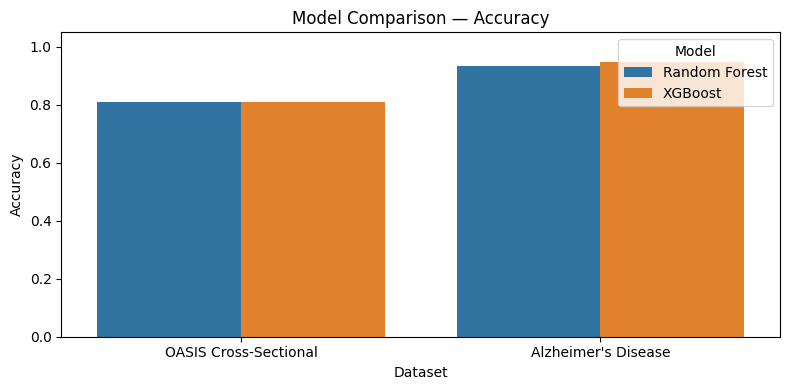

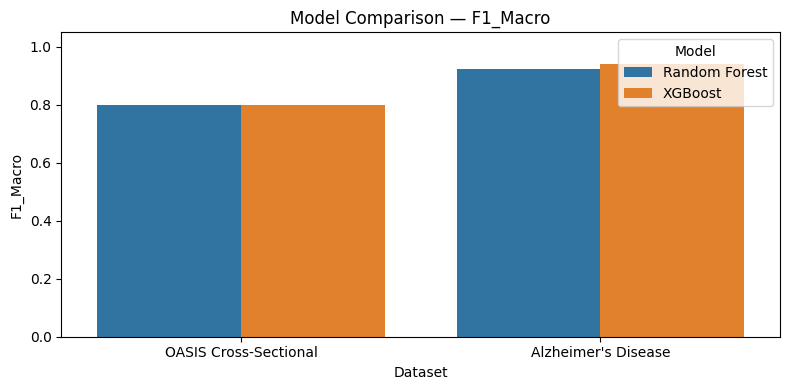

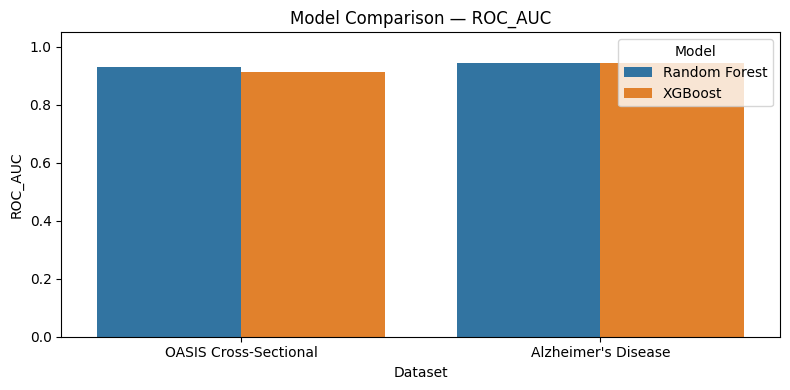

In [16]:
for metric in ["Accuracy", "F1_Macro", "ROC_AUC"]:
    plt.figure(figsize=(8, 4))
    sns.barplot(data=results_df, x="Dataset", y=metric, hue="Model")
    plt.title(f"Model Comparison — {metric}")
    plt.ylim(0, 1.05)
    plt.tight_layout()
    plt.show()


**Step 12 — Show prediction outputs and feature importance
KDD stage: Interpretation and knowledge discovery**

In [17]:
os.makedirs("prediction_outputs", exist_ok=True)

for (dataset_name, model_name), pred in predictions.items():
    y_test = pred["actual"]
    y_pred = pred["predicted"]
    y_prob = pred["probability_class_1"]

    output_df = pd.DataFrame({
        "Actual_Class": y_test.to_numpy(),
        "Predicted_Class": y_pred,
        "Probability_Class_1": y_prob,
        "Correct_Prediction": (y_test.to_numpy() == y_pred)
    })

    filename = (
        dataset_name.lower().replace(" ", "_").replace("'", "")
        + "_"
        + model_name.lower().replace(" ", "_")
        + "_predictions.csv"
    )

    output_df.to_csv(os.path.join("prediction_outputs", filename), index=False)
    print(f"Saved prediction output: prediction_outputs/{filename}")


Saved prediction output: prediction_outputs/oasis_cross-sectional_random_forest_predictions.csv
Saved prediction output: prediction_outputs/oasis_cross-sectional_xgboost_predictions.csv
Saved prediction output: prediction_outputs/alzheimers_disease_random_forest_predictions.csv
Saved prediction output: prediction_outputs/alzheimers_disease_xgboost_predictions.csv


In [ ]:
for key, pred in predictions.items():
    dataset_name, model_name = key

    print(f"\n{dataset_name} — {model_name}")

    sample_df = pd.DataFrame({
        "Actual": pred["actual"].to_numpy(),
        "Predicted": pred["predicted"],
        "Probability_Class_1": pred["probability_class_1"]
    })

    print(sample_df.head(10).round(4))


OASIS Cross-Sectional — Random Forest
   Actual  Predicted  Probability_Class_1
0       0          0               0.0200
1       1          1               0.8533
2       0          0               0.2333
3       1          1               0.9100
4       1          1               0.9267
5       1          1               0.9333
6       0          0               0.3467
7       1          1               0.8133
8       1          1               0.8367
9       0          0               0.0233

OASIS Cross-Sectional — XGBoost
   Actual  Predicted  Probability_Class_1
0       0          0               0.0093
1       1          1               0.9887
2       0          0               0.2251
3       1          1               0.9926
4       1          1               0.9974
5       1          1               0.9978
6       0          0               0.0361
7       1          1               0.9884
8       1          1               0.9444
9       0          0               0.0059

OAS

In [18]:
os.makedirs("feature_importance", exist_ok=True)

for dataset_name, models in experiments.items():
    for model_name, (pipeline, X_test, y_test) in models.items():
        preprocessor = pipeline.named_steps["preprocessor"]
        classifier = pipeline.named_steps["model"]

        feature_names = preprocessor.get_feature_names_out()
        importance_values = classifier.feature_importances_

        importance_df = pd.DataFrame({
            "Feature": feature_names,
            "Importance": importance_values
        }).sort_values("Importance", ascending=False)

        safe_name = (
            dataset_name.lower().replace(" ", "_").replace("'", "")
            + "_"
            + model_name.lower().replace(" ", "_")
        )

        importance_df.to_csv(f"feature_importance/{safe_name}_importance.csv", index=False)
        print(f"Saved feature importance: feature_importance/{safe_name}_importance.csv")


Saved feature importance: feature_importance/oasis_cross-sectional_random_forest_importance.csv
Saved feature importance: feature_importance/oasis_cross-sectional_xgboost_importance.csv
Saved feature importance: feature_importance/alzheimers_disease_random_forest_importance.csv
Saved feature importance: feature_importance/alzheimers_disease_xgboost_importance.csv


In [ ]:
train_subjects = set(
    long_model.loc[Xl_train.index, "Subject_ID"]
) if Xl_train.index.isin(long_model.index).all() else set()

test_subjects = set(
    long_model.loc[Xl_test.index, "Subject_ID"]
) if Xl_test.index.isin(long_model.index).all() else set()

print("Training subjects:", len(train_subjects))
print("Testing subjects:", len(test_subjects))
print("Overlapping subjects:", len(train_subjects & test_subjects))

Training subjects: 120
Testing subjects: 30
Overlapping subjects: 0


In [ ]:
datasets = {
    "OASIS Cross-Sectional": oasis_cross,
    "OASIS Longitudinal": oasis_long,
    "Alzheimer's Disease": alz_data
}

In [19]:
import os
import zipfile
from google.colab import files

# Define files and folders to package
files_to_download = ["model_comparison_results.csv"]
folders_to_download = ["prediction_outputs", "feature_importance"]
zip_filename = "alzheimers_project_outputs.zip"

print("Packaging files and folders into a zip archive...")
with zipfile.ZipFile(zip_filename, 'w', zipfile.ZIP_DEFLATED) as zipf:
    # Add individual files
    for file in files_to_download:
        if os.path.exists(file):
            zipf.write(file, file)
            print(f"Added file: {file}")
        else:
            print(f"Warning: File {file} not found.")

    # Add directory trees
    for folder in folders_to_download:
        if os.path.exists(folder):
            for root, dirs, files_in_dir in os.walk(folder):
                for file in files_in_dir:
                    filepath = os.path.join(root, file)
                    # Keep folder structure inside zip
                    arcname = os.path.relpath(filepath, os.path.dirname(folder))
                    zipf.write(filepath, arcname)
            print(f"Added folder: {folder}/")
        else:
            print(f"Warning: Folder {folder} not found.")

print(f"\nZip archive '{zip_filename}' created successfully.")
print("Triggering local browser download...")
files.download(zip_filename)

Packaging files and folders into a zip archive...
Added file: model_comparison_results.csv
Added folder: prediction_outputs/
Added folder: feature_importance/

Zip archive 'alzheimers_project_outputs.zip' created successfully.
Triggering local browser download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>